In [596]:
%load_ext autoreload
%autoreload 2
import warnings
warnings.filterwarnings('ignore')

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [597]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
pd.options.display.max_columns=500
pd.options.display.max_rows=200
pd.options.display.float_format = "{:.3e}".format

In [598]:
path_dados = r"C:\Python - Projects\Aulas WeCogno\Trabalho - Inadimplência\data\raw"

cad = pd.read_parquet(f'{path_dados}/base_cadastral.parquet')
sub = pd.read_parquet(f'{path_dados}/base_submissao.parquet') # por ultimo
hist_emp = pd.read_parquet(f'{path_dados}/historico_emprestimos.parquet')
hist_parc = pd.read_parquet(f'{path_dados}/historico_parcelas.parquet')

In [599]:
cad.head(1) # tem bastante categorica

,id_cliente,sexo,data_nascimento,qtd_filhos,qtd_membros_familia,renda_anual,tipo_renda,ocupacao,tipo_organizacao,nivel_educacao,estado_civil,tipo_moradia,possui_carro,possui_imovel,nota_regiao_cliente,nota_regiao_cliente_cidade
0,100023,Feminino,1994-01-30,1,2.000e+00,"90.000,00",Servidor público,Equipe administrativa,Educação infantil,Ensino superior,Solteiro,Casa ou apartamento,Não,Sim,2,2


In [600]:
sub.head(1) #

,id_cliente,data_solicitacao,dia_semana_solicitacao,hora_solicitacao,tipo_contrato,valor_credito,valor_bem,valor_parcela
0,100023,2025-02-24,segunda-feira,12:28:44,Financiamento de consumo,5.445e+05,4.545e+05,1.756e+04


In [601]:
hist_emp.head(1)

,id_contrato,id_cliente,tipo_contrato,status_contrato,data_decisao,data_liberacao,data_primeiro_vencimento,data_ultimo_vencimento_original,data_ultimo_vencimento,data_encerramento,valor_solicitado,valor_credito,valor_bem,valor_parcela,valor_entrada,percentual_entrada,qtd_parcelas_planejadas,taxa_juros_padrao,taxa_juros_promocional,tipo_pagamento,finalidade_emprestimo,tipo_cliente,faixa_rendimento,tipo_portfolio,tipo_produto,categoria_bem,combinacao_produto,setor_vendedor,canal_venda,area_venda,dia_semana_solicitacao,hora_solicitacao,indicador_ultima_solicitacao_contrato,indicador_ultima_solicitacao_dia,motivo_recusa,acompanhantes_cliente,indicador_seguro_contratado
0,2802425,108129,Empréstimo em dinheiro,Aprovado,2024-08-29,NaN,2024-09-28,2027-08-14,NaN,NaN,6.075e+05,6.797e+05,6.075e+05,2.519e+04,NaN,NaN,3.600e+01,NaN,NaN,Não informado,Não informado,Recorrente,baixa ação,Dinheiro,venda cruzada,Não informado,Dinheiro venda cruzada: low,Não informado,Central de atendimento,-1,quinta-feira,11:05:09,Sim,1,Não se aplica,Desacompanhado,1.000e+00


# Ingestão

## historico_parcelas

In [602]:
hist_parc.head(1)

,id_contrato,id_cliente,versao_parcela,numero_parcela,data_prevista_pagamento,data_real_pagamento,valor_previsto_parcela,valor_pago_parcela
0,1594684,100193,0.000e+00,56,2021-12-21,2021-12-21,3.019e+02,3.019e+02


In [603]:
hist_parc.drop_duplicates()

,id_contrato,id_cliente,versao_parcela,numero_parcela,data_prevista_pagamento,data_real_pagamento,valor_previsto_parcela,valor_pago_parcela
0,1594684,100193,0.000e+00,56,2021-12-21,2021-12-21,3.019e+02,3.019e+02
1,1995642,134723,1.000e+00,38,2021-08-09,2021-08-04,1.295e+04,1.295e+04
2,1720935,176364,1.000e+00,9,2024-03-06,2024-03-04,6.119e+04,6.119e+04
3,1439208,154898,1.000e+00,20,2024-08-11,2024-08-07,8.851e+03,8.851e+03
4,1640082,172575,1.000e+00,4,2022-11-15,2022-11-10,8.720e+03,8.720e+03
...,...,...,...,...,...,...,...,...
1664373,1323172,217502,1.000e+00,2,2022-04-30,2022-07-13,1.145e+04,1.356e+04
1664376,1780171,119721,1.000e+00,7,2020-10-18,2020-09-22,2.563e+03,3.080e+03
1664377,2855181,460177,0.000e+00,4,2023-09-12,2023-09-20,2.422e+03,2.234e+03
1664380,2506179,437996,0.000e+00,55,2020-08-11,2020-08-11,2.250e+03,2.299e+03


In [604]:
hist_parc.data_real_pagamento.isnull().sum()

np.int64(3655)

In [605]:
hist_parc[hist_parc.data_prevista_pagamento== hist_parc.data_prevista_pagamento.max()]

,id_contrato,id_cliente,versao_parcela,numero_parcela,data_prevista_pagamento,data_real_pagamento,valor_previsto_parcela,valor_pago_parcela
351106,1627545,197516,1.000e+00,14,2025-02-22,2025-02-21,6.673e+04,6.673e+04
712116,1746828,280883,0.000e+00,18,2025-02-22,2025-02-22,5.576e+03,5.576e+03
808960,1031863,350738,0.000e+00,39,2025-02-22,2025-02-17,1.125e+04,1.125e+04
840373,1606187,376101,1.000e+00,4,2025-02-22,2025-02-17,6.153e+04,6.153e+04


In [606]:
hist_parc['data_prevista_pagamento'] = pd.to_datetime(hist_parc['data_prevista_pagamento'], format='%Y-%m-%d', errors='coerce')
hist_parc['data_real_pagamento'] = pd.to_datetime(hist_parc['data_real_pagamento'], format='%Y-%m-%d') # não vou preencher por enquanto ! fillna(pd.Timestamp('2025-01-31'))

hist_parc['dias_atraso'] = (hist_parc['data_real_pagamento'] - hist_parc['data_prevista_pagamento']).dt.days.astype('Int64')


In [607]:
## Criando feature de dias_atraso -> checando inadimplência pré-tratamento
hist_parc['t90'] = hist_parc.dias_atraso >= 90 # classico para banco
hist_parc['t60'] = hist_parc.dias_atraso >= 60
hist_parc['t30'] = hist_parc.dias_atraso >= 30
hist_parc['t1'] = hist_parc.dias_atraso >= 1 #mais agressivo - 14,07% é muito. Falência

In [608]:
## Checando inadimplência inicial
hist_parc[['t90', 't60', 't30', 't1']].sum()/len(hist_parc)*100

t90   2.417e-01
t60   6.501e-01
t30   1.502e+00
t1    1.407e+01
dtype: Float64

### Problemas encontrados e soluções

#### 1) `versao_parcela` varia para um mesmo `numero_parcela`, de um determinado contrato de um cliente. 

Decisão: Manter a parcela mais recente (maior valor)

In [609]:
# grp -> agrupar parcelas parciais: soma os valores valor_pago_parcela nas mesmas versoes
grp = hist_parc.groupby(['id_contrato','id_cliente','numero_parcela']).agg(
    versao_parcela = ('versao_parcela', 'max'),
    valor_pago_parcela_tot = ('valor_pago_parcela', 'sum'),
    valor_previsto_parcela = ('valor_previsto_parcela', 'first'),
    dias_atraso_max = ('dias_atraso', 'max')
).reset_index()
grp['deficit'] = grp.valor_previsto_parcela - grp.valor_pago_parcela_tot
grp['deficit_perc'] = grp.deficit/grp.valor_previsto_parcela
grp

,id_contrato,id_cliente,numero_parcela,versao_parcela,valor_pago_parcela_tot,valor_previsto_parcela,dias_atraso_max,deficit,deficit_perc
0,1000003,252457,1,1.000e+00,4.951e+03,4.951e+03,-14,0.000e+00,0.000e+00
1,1000003,252457,2,1.000e+00,4.951e+03,4.951e+03,-17,0.000e+00,0.000e+00
2,1000003,252457,3,1.000e+00,4.951e+03,4.951e+03,-15,0.000e+00,0.000e+00
3,1000013,215520,1,1.000e+00,1.335e+04,1.335e+04,-6,0.000e+00,0.000e+00
4,1000013,215520,2,1.000e+00,1.335e+04,1.335e+04,-6,0.000e+00,0.000e+00
...,...,...,...,...,...,...,...,...,...
1574406,2870412,466247,8,0.000e+00,1.545e+05,1.545e+05,0,0.000e+00,0.000e+00
1574407,2870412,466247,9,0.000e+00,1.545e+05,1.545e+05,0,0.000e+00,0.000e+00
1574408,2870412,466247,10,0.000e+00,3.096e+05,1.545e+05,1,-1.552e+05,-1.005e+00
1574409,2870415,466248,1,1.000e+00,4.912e+02,4.912e+02,0,0.000e+00,0.000e+00


In [610]:
chave = ['id_contrato', 'id_cliente', 'numero_parcela', 'versao_parcela']

parc = grp.merge(hist_parc.drop(columns=['dias_atraso', 'valor_previsto_parcela', 'valor_pago_parcela']) # mantém apenas o último pagamento e dropa as multiplas entradas
                 .sort_values('data_real_pagamento', na_position='first')
                 .drop_duplicates(subset=chave, keep='last'),
          on=chave,
          how='left')

ord_parc = ['id_contrato', 'id_cliente', 'numero_parcela', 'versao_parcela', 'valor_previsto_parcela', 
            'valor_pago_parcela_tot', 'deficit', 'deficit_perc', 'data_prevista_pagamento', 'data_real_pagamento',
            'dias_atraso_max']
parc = parc[ord_parc].sort_values(by=['id_contrato', 'id_cliente', 'numero_parcela','versao_parcela'])

In [611]:
## atraso com máx de dias_atraso daquela parcela
parc['t1'] = parc.dias_atraso_max >= 1
parc['t30'] = parc.dias_atraso_max >= 30
parc['t60'] = parc.dias_atraso_max >= 60
parc['t90'] = parc.dias_atraso_max >= 90 # classico para banco

In [612]:
display(hist_parc[['t90', 't60', 't30', 't1']].sum()/len(hist_parc)*100) # taxas de inadimplência por períodos de atraso de pagamento (nas versões mais atuais)
display(parc[['t90', 't60', 't30', 't1']].sum()/len(parc)*100)

t90   2.417e-01
t60   6.501e-01
t30   1.502e+00
t1    1.407e+01
dtype: Float64

t90   2.513e-01
t60   6.792e-01
t30   1.568e+00
t1    1.450e+01
dtype: Float64

### 2) Como inadimplência varia de acordo com tempo de atraso

In [613]:
tst_dias_atraso = parc.drop(columns=['t90', 't60', 't30', 't1'])

In [614]:
for i in range(1, 181):
    tst_dias_atraso[f't{i}'] = tst_dias_atraso['dias_atraso_max'] >= i


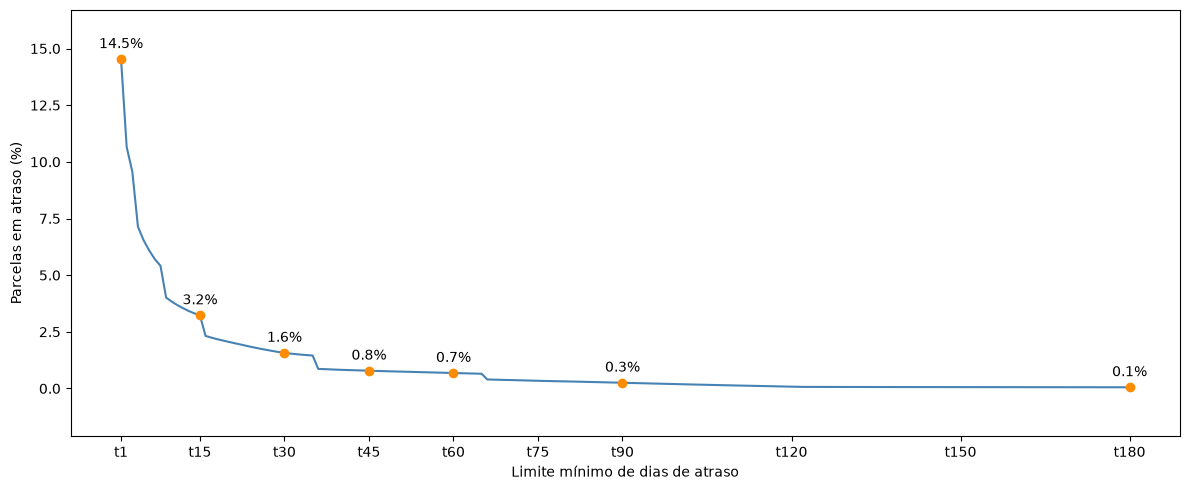

In [615]:

dias = list(range(1, 181))
taxas = tst_dias_atraso[[f"t{dia}" for dia in dias]].mean() * 100
taxas.index = dias

destaques = [1, 15, 30, 45, 60, 90, 180]
mobs = [1, *range(15, 91, 15), *range(120, 181, 30)]

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(dias, taxas, color="steelblue")
ax.scatter(destaques, taxas.loc[destaques], color="darkorange", zorder=3)

for dia in destaques:
    taxa = taxas.loc[dia]
    ax.annotate(
        f"{taxa:.1f}%",
        (dia, taxa),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
    )

ax.set_xticks(mobs, labels=[f"t{dia}" for dia in mobs])
ax.set_xlabel("Limite mínimo de dias de atraso")
ax.set_ylabel("Parcelas em atraso (%)")
ax.margins(y=0.15)
fig.tight_layout()
plt.show()

-> convém manter atraso >= 15 dias como valor mínimo de atraso para inadimplência! (Regra do cotovelo)

### 3) Comparando possíveis cenários de taxa de inadimplência

Inadimplência -> definido como contratos cuja empresa credora não tem mais confiança de que haverá pagamento.

atraso != inadimplência!

3 Condições principais:

   - Deve existir atraso considerável -> definir com base no gráfico anterior
   - deficit > 1 (pelo menos 1 real de débito pendente)
   - deficit_perc > 5% (1 real deve representar ao menos 5% do valor total)

In [616]:
parc.id_contrato.nunique()

122867

In [617]:
parc.loc[(parc.dias_atraso_max>0)&(parc.deficit_perc<0.01)].sort_values(by="deficit_perc")


,id_contrato,id_cliente,numero_parcela,versao_parcela,valor_previsto_parcela,valor_pago_parcela_tot,deficit,deficit_perc,data_prevista_pagamento,data_real_pagamento,dias_atraso_max,t1,t30,t60,t90
83579,1110271,442388,1,3.000e+00,3.249e+02,4.982e+04,-4.950e+04,-1.524e+02,2024-11-05,2024-11-29,24,True,False,False,False
627008,1862316,124874,10,2.000e+00,4.290e+02,2.869e+04,-2.826e+04,-6.587e+01,2024-04-15,2024-04-18,3,True,False,False,False
949356,2320121,396084,1,3.000e+00,2.325e+02,1.463e+04,-1.440e+04,-6.194e+01,2024-11-06,2024-11-22,16,True,False,False,False
146821,1202619,323070,1,3.000e+00,1.633e+02,8.263e+03,-8.100e+03,-4.960e+01,2024-11-22,2024-12-02,10,True,False,False,False
1169699,2641180,291467,10,2.000e+00,3.835e+04,1.228e+06,-1.189e+06,-3.102e+01,2024-08-22,2024-10-07,46,True,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
839038,2166904,419596,12,1.000e+00,5.314e+03,5.275e+03,3.897e+01,7.333e-03,2022-04-25,2022-04-28,3,True,False,False,False
56209,1076329,227920,9,1.000e+00,7.192e+03,7.136e+03,5.638e+01,7.840e-03,2023-12-25,2023-12-28,3,True,False,False,False
801802,2113935,231004,6,2.000e+00,2.679e+04,2.656e+04,2.326e+02,8.683e-03,2022-04-26,2022-05-01,5,True,False,False,False
211315,1285728,111295,1,1.000e+00,5.497e+03,5.448e+03,4.914e+01,8.940e-03,2021-07-29,2021-08-06,8,True,False,False,False


In [618]:
parc.head()

,id_contrato,id_cliente,numero_parcela,versao_parcela,valor_previsto_parcela,valor_pago_parcela_tot,deficit,deficit_perc,data_prevista_pagamento,data_real_pagamento,dias_atraso_max,t1,t30,t60,t90
0,1000003,252457,1,1.000e+00,4.951e+03,4.951e+03,0.000e+00,0.000e+00,2024-11-19,2024-11-05,-14,False,False,False,False
1,1000003,252457,2,1.000e+00,4.951e+03,4.951e+03,0.000e+00,0.000e+00,2024-12-19,2024-12-02,-17,False,False,False,False
2,1000003,252457,3,1.000e+00,4.951e+03,4.951e+03,0.000e+00,0.000e+00,2025-01-18,2025-01-03,-15,False,False,False,False
3,1000013,215520,1,1.000e+00,1.335e+04,1.335e+04,0.000e+00,0.000e+00,2021-05-23,2021-05-17,-6,False,False,False,False
4,1000013,215520,2,1.000e+00,1.335e+04,1.335e+04,0.000e+00,0.000e+00,2021-06-22,2021-06-16,-6,False,False,False,False


In [619]:
# Visualizando qtd de registros em diferentes tempos de atraso
display(parc[['t90', 't60', 't30', 't1']].sum())
display(parc[['t90', 't60', 't30', 't1']].sum()/len(parc)*100)

t90      3957
t60     10694
t30     24684
t1     228268
dtype: Int64

t90   2.513e-01
t60   6.792e-01
t30   1.568e+00
t1    1.450e+01
dtype: Float64

## base_cadastral - cad

In [620]:
len(cad)

50600

In [621]:
## criando feats_cad para passar depois no merge -> id_cliente e sexo já serão presentes.
feats_cad = [i for i in cad.columns.drop(["id_cliente", "sexo"])]

In [622]:
print(feats_cad)

['data_nascimento', 'qtd_filhos', 'qtd_membros_familia', 'renda_anual', 'tipo_renda', 'ocupacao', 'tipo_organizacao', 'nivel_educacao', 'estado_civil', 'tipo_moradia', 'possui_carro', 'possui_imovel', 'nota_regiao_cliente', 'nota_regiao_cliente_cidade']


In [623]:
cad.head(1)

,id_cliente,sexo,data_nascimento,qtd_filhos,qtd_membros_familia,renda_anual,tipo_renda,ocupacao,tipo_organizacao,nivel_educacao,estado_civil,tipo_moradia,possui_carro,possui_imovel,nota_regiao_cliente,nota_regiao_cliente_cidade
0,100023,Feminino,1994-01-30,1,2.000e+00,"90.000,00",Servidor público,Equipe administrativa,Educação infantil,Ensino superior,Solteiro,Casa ou apartamento,Não,Sim,2,2


In [624]:
import re
from unicodedata import normalize

# Conversão de texto para float (renda)
def fix_renda(txt):

    rgx = '[\d,]'
    res = ''.join(re.findall(rgx, txt)).replace(',', '.')
    if res == '':
        return '0'
    return res


## arrumando strings: strings -> padronizar lower_case, tirar espaços e acentos


def fix_strings_cat(txt):
    return re.sub(r"[\u0300-\u036f]", "", normalize("NFD", txt.strip().lower()))

In [625]:
from pandas.api.types import is_numeric_dtype
## drop duplicadas (sem informação, não tem como escolher qual é a mais atual -> falta informação de timestamp/versao/data referencia)
## escolhido manter os registros com menor renda, mesmo que esta seja negativa!
cad.duplicated(subset=['id_cliente']).sum()
cad = cad.sort_values(['id_cliente', 'renda_anual']).drop_duplicates(subset=['id_cliente'], keep='first')

# coluna sexo -> dropar:
cad = cad.drop(columns=['sexo'], errors='ignore')

## possui_carro/possui_imovel -> binária. Se nao tiver informação -> assumir 0!
for coluna in ["possui_carro", "possui_imovel"]:
    valores = cad[coluna].map(lambda x: fix_strings_cat(x) if isinstance(x, str) else x,
        na_action="ignore")
    cad[coluna] = valores.replace({"sim": 1, "nao": 0, "nao informado": pd.NA}).astype("Int64").fillna(0)

## data_nascimento -> datetime
cad['data_nascimento'] = pd.to_datetime(cad.data_nascimento, format="%Y-%m-%d", errors="coerce")
cad['data_nascimento'] = cad['data_nascimento'].replace({
    pd.Timestamp("1901-05-20"): pd.NaT,
    pd.Timestamp("2030-01-01"): pd.NaT    
})
filtro = cad['data_nascimento'].isna() | cad['data_nascimento'].gt(pd.Timestamp('2012-01-01'))
cad.loc[filtro, 'data_nascimento'] = cad.loc[~filtro, 'data_nascimento'].median() # idades de 2012 -> transformar para mediana ()

    
## qtd_filhos (int64) >= 0, qtd_membros_familia (int64) >= 1. Assumir valores mínimos se não informado.
cad['qtd_filhos'] = cad['qtd_filhos'].astype('Int64').clip(lower=0).fillna(0)
cad['qtd_membros_familia'] = cad['qtd_membros_familia'].astype('Int64').clip(lower=1).fillna(1)

## renda -> transformar em float e tirar nulos (-> 0)
if not is_numeric_dtype(cad['renda_anual']):
    cad['renda_anual'] = cad.renda_anual.apply(lambda x: fix_renda(x))

cad.renda_anual = cad.renda_anual.fillna(0).astype(float)

## ajustando ['tipo_renda', 'ocupacao', 'tipo_organizacao', 'nivel_educacao', 'estado_civil', 'tipo_moradia']

for column in ['tipo_renda', 'ocupacao', 'tipo_organizacao', 'nivel_educacao', 'estado_civil', 'tipo_moradia']:
    cad[column] = cad[column].fillna("nao informado").apply(lambda x: fix_strings_cat(x))

### Resumo de alterações e checagens



## historico_emprestimos

In [626]:
hist_emp.head(1)

,id_contrato,id_cliente,tipo_contrato,status_contrato,data_decisao,data_liberacao,data_primeiro_vencimento,data_ultimo_vencimento_original,data_ultimo_vencimento,data_encerramento,valor_solicitado,valor_credito,valor_bem,valor_parcela,valor_entrada,percentual_entrada,qtd_parcelas_planejadas,taxa_juros_padrao,taxa_juros_promocional,tipo_pagamento,finalidade_emprestimo,tipo_cliente,faixa_rendimento,tipo_portfolio,tipo_produto,categoria_bem,combinacao_produto,setor_vendedor,canal_venda,area_venda,dia_semana_solicitacao,hora_solicitacao,indicador_ultima_solicitacao_contrato,indicador_ultima_solicitacao_dia,motivo_recusa,acompanhantes_cliente,indicador_seguro_contratado
0,2802425,108129,Empréstimo em dinheiro,Aprovado,2024-08-29,NaN,2024-09-28,2027-08-14,NaN,NaN,6.075e+05,6.797e+05,6.075e+05,2.519e+04,NaN,NaN,3.600e+01,NaN,NaN,Não informado,Não informado,Recorrente,baixa ação,Dinheiro,venda cruzada,Não informado,Dinheiro venda cruzada: low,Não informado,Central de atendimento,-1,quinta-feira,11:05:09,Sim,1,Não se aplica,Desacompanhado,1.000e+00


In [627]:
hist_emp.info()

<class 'pandas.DataFrame'>
RangeIndex: 211944 entries, 0 to 211943
Data columns (total 37 columns):
 #   Column                                 Non-Null Count   Dtype  
---  ------                                 --------------   -----  
 0   id_contrato                            211944 non-null  int64  
 1   id_cliente                             211944 non-null  int64  
 2   tipo_contrato                          211944 non-null  str    
 3   status_contrato                        211944 non-null  str    
 4   data_decisao                           211944 non-null  str    
 5   data_liberacao                         7709 non-null    str    
 6   data_primeiro_vencimento               122712 non-null  str    
 7   data_ultimo_vencimento_original        116696 non-null  str    
 8   data_ultimo_vencimento                 96816 non-null   str    
 9   data_encerramento                      95183 non-null   str    
 10  valor_solicitado                       211944 non-null  float64
 11

Quais colunas manter:

- float: [valor_solicitado,valor_credito, valor_bem, valor_parcela, valor_entrada, tipo_contrato]

- int: ['indicador_ultima_solicitacao_contrato', 'indicador_ultima_solicitacao_dia', 'indicador_seguro_contratado', 'qtd_parcelas_planejadas']

- datetime: ['proxy_data_solicitacao', 'hora_solicitacao'] (criado a partir de data_liberacao e data_decisao)

- cat: ['tipo_contrato', 'status_contrato',  'tipo_pagamento', 'finalidade_emprestimo',
       'tipo_cliente', 'faixa_rendimento', 'tipo_portfolio', 'tipo_produto',
       'categoria_bem', 'combinacao_produto', 'setor_vendedor', 'canal_venda',
       'area_venda', 'dia_semana_solicitacao', 'motivo_recusa',
       'acompanhantes_cliente']


In [628]:
hist_emp[hist_emp.valor_entrada==0]

,id_contrato,id_cliente,tipo_contrato,status_contrato,data_decisao,data_liberacao,data_primeiro_vencimento,data_ultimo_vencimento_original,data_ultimo_vencimento,data_encerramento,valor_solicitado,valor_credito,valor_bem,valor_parcela,valor_entrada,percentual_entrada,qtd_parcelas_planejadas,taxa_juros_padrao,taxa_juros_promocional,tipo_pagamento,finalidade_emprestimo,tipo_cliente,faixa_rendimento,tipo_portfolio,tipo_produto,categoria_bem,combinacao_produto,setor_vendedor,canal_venda,area_venda,dia_semana_solicitacao,hora_solicitacao,indicador_ultima_solicitacao_contrato,indicador_ultima_solicitacao_dia,motivo_recusa,acompanhantes_cliente,indicador_seguro_contratado
8,1009986,360684,Financiamento de consumo,Aprovado,2023-03-28,NaN,2023-04-28,2023-09-25,2023-09-25,2023-10-01,5.760e+04,6.064e+04,5.760e+04,1.145e+04,0.000e+00,0.000e+00,6.000e+00,NaN,NaN,Dinheiro pelo banco,Não se aplica,Novo,média,Ponto de venda,Não informado,Móveis,Ponto de venda indústria com juros,Móveis,Loja física,95,terça-feira,14:12:26,Sim,1,Não se aplica,Desacompanhado,0.000e+00
23,1103699,179380,Empréstimo em dinheiro,Aprovado,2021-11-18,NaN,2021-12-19,2022-09-15,2022-09-15,2022-09-18,3.290e+04,3.561e+04,3.290e+04,4.565e+03,0.000e+00,0.000e+00,1.000e+01,NaN,NaN,Dinheiro pelo banco,Não se aplica,Recorrente,alta,Ponto de venda,Não informado,Eletrônicos de consumo,Ponto de venda casa com juros,Eletrônicos de consumo,Rede nacional,230,quinta-feira,09:55:50,Sim,1,Não se aplica,Desacompanhado,0.000e+00
28,1744003,351953,Empréstimo em dinheiro,Aprovado,2023-05-12,NaN,2023-06-12,2023-11-09,2023-11-09,2023-11-11,1.206e+05,1.269e+05,1.206e+05,2.383e+04,0.000e+00,0.000e+00,6.000e+00,NaN,NaN,Dinheiro pelo banco,Não se aplica,Novo,média,Ponto de venda,Não informado,Computadores,Ponto de venda casa com juros,Eletrônicos de consumo,Rede nacional,3000,sexta-feira,17:32:10,Sim,1,Não se aplica,NaN,0.000e+00
33,1845535,343206,Financiamento de consumo,Aprovado,2019-03-01,NaN,2019-03-31,2020-02-24,2019-12-26,2019-12-29,2.250e+05,2.398e+05,2.250e+05,2.623e+04,0.000e+00,0.000e+00,1.200e+01,NaN,NaN,Dinheiro pelo banco,Não informado,Recorrente,alta,Dinheiro,venda cruzada,Celular,Dinheiro captação externa: alta,Não informado,Agências de crédito e dinheiro,-1,sexta-feira,16:33:26,Sim,1,Não se aplica,Desacompanhado,1.000e+00
37,1150154,121687,Financiamento de consumo,Aprovado,2023-10-17,NaN,2023-11-17,2024-04-15,2023-12-17,2023-12-24,1.499e+04,1.781e+04,1.499e+04,3.423e+03,0.000e+00,0.000e+00,6.000e+00,NaN,NaN,Dinheiro pelo banco,Não se aplica,Recorrente,média,Ponto de venda,Não informado,Eletrônicos de consumo,Ponto de venda casa com juros,Eletrônicos de consumo,Regional ou local,5,terça-feira,13:49:59,Sim,1,Não se aplica,NaN,0.000e+00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
211905,2870378,466235,Empréstimo em dinheiro,Aprovado,2019-01-11,NaN,2019-02-19,2019-11-16,2019-11-16,2019-11-22,1.636e+05,1.569e+05,1.387e+05,2.366e+04,0.000e+00,0.000e+00,1.000e+01,NaN,NaN,Dinheiro pelo banco,Não informado,Recorrente,alta,Dinheiro,venda cruzada,Não informado,Dinheiro venda cruzada: alta,Não informado,Agências de crédito e dinheiro,-1,quarta-feira,15:32:51,Sim,1,Não se aplica,Desacompanhado,1.000e+00
211909,2870382,466237,Financiamento de consumo,Cancelado,2023-07-20,NaN,NaN,NaN,NaN,NaN,1.208e+05,1.252e+05,1.167e+05,NaN,0.000e+00,0.000e+00,NaN,NaN,NaN,Dinheiro pelo banco,Não se aplica,Recorrente,média,Ponto de venda,Não informado,Eletrônicos de consumo,Ponto de venda casa com juros,Eletrônicos de consumo,Loja física,250,quarta-feira,20:24:05,Sim,1,Histórico de crédito,NaN,0.000e+00
211914,2870387,466238,Financiamento de consumo,Aprovado,2025-01-07,NaN,2025-02-17,2026-07-12,2025-01-28,2025-02-08,4.425e+04,4.803e+04,4.611e+04,3.063e+03,0.000e+00,0.000e+00,1.800e+01,NaN,NaN,Dinheiro pelo banco,Não se aplica,Recorrente,alta,Ponto de venda,Não informado,Áudio e vídeo,Ponto de venda casa c

In [ ]:
from pandas.api.types import is_string_dtype

## limpar dados de colunas str -> sem duplicatas devido à padronização do texto
for i in hist_emp.columns:
    if not re.match(r'data_', i) and is_string_dtype(hist_emp[i]) and i!='hora_solicitacao':
      hist_emp[i] = hist_emp[i].replace({np.nan: 'nao informado'}).map(lambda x: fix_strings_cat(x))

hist_emp['area_venda'] = hist_emp.area_venda.astype(str)
hist_emp["finalidade_emprestimo"] = hist_emp["finalidade_emprestimo"].str.replace({'cliente nao informou a finalidade':'nao informado'})

 
## binarias: indicador_seguro_contratado: dummy -> possui nulos. As outras ['indicador_ultima_solicitacao_dia', 'indicador_ultima_solicitacao_dia'] não precisa
hist_emp['indicador_seguro_contratado'] = hist_emp['indicador_seguro_contratado'].astype('Int64')
hist_emp['indicador_ultima_solicitacao_contrato'] = hist_emp.indicador_ultima_solicitacao_contrato.replace({'sim': '1', 'nao': '0'}).astype('Int64')

## datas: criar duas feats: proxy_data_solicitacao e tempo_contrato_original
hist_emp['proxy_data_solicitacao'] = pd.to_datetime(hist_emp.data_liberacao.fillna(hist_emp.data_decisao), format="%Y-%m-%d", errors="coerce")
hist_emp['hora_solicitacao'] = pd.to_datetime(hist_emp.hora_solicitacao).dt.strftime("%H:%M:%S")
hist_emp['data_encerramento'] = pd.to_datetime(hist_emp.data_encerramento, format='%Y-%m-%d', errors='coerce')

## valor_bem -> fillna com valor_solicitado
hist_emp['valor_bem'] = hist_emp["valor_bem"].fillna(hist_emp.valor_solicitado)
hist_emp['indicador_valor_entrada_ausente'] = hist_emp.valor_entrada.isna().astype('int8')
hist_emp['valor_entrada'] = hist_emp.valor_entrada.fillna(0)
hist_emp['percentual_entrada'] = hist_emp.percentual_entrada.fillna(0)

In [630]:
hist_emp.info()

<class 'pandas.DataFrame'>
RangeIndex: 211944 entries, 0 to 211943
Data columns (total 39 columns):
 #   Column                                 Non-Null Count   Dtype         
---  ------                                 --------------   -----         
 0   id_contrato                            211944 non-null  int64         
 1   id_cliente                             211944 non-null  int64         
 2   tipo_contrato                          211944 non-null  str           
 3   status_contrato                        211944 non-null  str           
 4   data_decisao                           211944 non-null  str           
 5   data_liberacao                         7709 non-null    str           
 6   data_primeiro_vencimento               122712 non-null  str           
 7   data_ultimo_vencimento_original        116696 non-null  str           
 8   data_ultimo_vencimento                 96816 non-null   str           
 9   data_encerramento                      95183 non-null   dat

In [637]:
sub.head(1)

,id_cliente,data_solicitacao,dia_semana_solicitacao,hora_solicitacao,tipo_contrato,valor_credito,valor_bem,valor_parcela
0,100023,2025-02-24,segunda-feira,12:28:44,Financiamento de consumo,5.445e+05,4.545e+05,1.756e+04


In [ ]:
## Organizando as colunas 

feats_emp = ['valor_solicitado','proxy_data_solicitacao','dia_semana_solicitacao', 'hora_solicitacao', 'tipo_contrato', 'valor_credito', 'valor_bem', 'valor_parcela']
df_emp = hist_emp[['id_cliente', 'id_contrato'] + feats_emp].copy()
df_emp.info()

<class 'pandas.DataFrame'>
RangeIndex: 211944 entries, 0 to 211943
Data columns (total 29 columns):
 #   Column                                 Non-Null Count   Dtype         
---  ------                                 --------------   -----         
 0   id_cliente                             211944 non-null  int64         
 1   id_contrato                            211944 non-null  int64         
 2   valor_solicitado                       211944 non-null  float64       
 3   valor_credito                          211944 non-null  float64       
 4   valor_bem                              211944 non-null  float64       
 5   valor_parcela                          160679 non-null  float64       
 6   valor_entrada                          211944 non-null  float64       
 7   indicador_ultima_solicitacao_contrato  211944 non-null  Int64         
 8   indicador_ultima_solicitacao_dia       211944 non-null  int64         
 9   indicador_seguro_contratado            126779 non-null  Int

In [635]:
# Checar colunas retiradas
hist_emp.columns[~hist_emp.columns.isin(df_emp.columns)]

Index(['data_decisao', 'data_liberacao', 'data_primeiro_vencimento',
       'data_ultimo_vencimento_original', 'data_ultimo_vencimento',
       'percentual_entrada', 'qtd_parcelas_planejadas', 'taxa_juros_padrao',
       'taxa_juros_promocional', 'indicador_valor_entrada_ausente'],
      dtype='str')

#### Explicando colunas dropadas

- data_decisao e data_liberacao -> vira proxy_data_solicitacao
- data_primeiro_vencimento e data_

In [371]:
df_emp.valor_entrada.value_counts(ascending=False, dropna=False)

valor_entrada
NaN          112286
0.000e+00     46855
4.500e+03      2717
9.000e+03      1917
1.350e+04      1250
              ...  
6.094e+03         1
2.114e+04         1
3.719e+04         1
9.006e+03         1
1.791e+04         1
Name: count, Length: 8649, dtype: int64

In [373]:
print(sub.data_solicitacao.min())
print(df_emp.proxy_data_solicitacao.max())


2025-02-04
2025-02-03 00:00:00


## base_submissao -> mesmas alterações que historico_emprestimos (mas apenas nas colunas presentes por enquanto)



In [334]:
sub.head(1)

,id_cliente,data_solicitacao,dia_semana_solicitacao,hora_solicitacao,tipo_contrato,valor_credito,valor_bem,valor_parcela
0,100023,2025-02-24,segunda-feira,12:28:44,Financiamento de consumo,5.445e+05,4.545e+05,1.756e+04


In [312]:
display(df_emp[df_emp.proxy_data_solicitacao>=pd.Timestamp("2025-02-04")])
display(df_emp)
display(sub.sort_values(by='data_solicitacao'))

,id_cliente,id_contrato,valor_solicitado,valor_credito,valor_bem,valor_parcela,valor_entrada,tipo_contrato,indicador_ultima_solicitacao_contrato,indicador_ultima_solicitacao_dia,indicador_seguro_contratado,indicador_ultima_solicitacao_contrato,indicador_ultima_solicitacao_dia,indicador_seguro_contratado,qtd_parcelas_planejadas,proxy_data_solicitacao,hora_solicitacao,tipo_contrato,status_contrato,tipo_pagamento,finalidade_emprestimo,tipo_cliente,faixa_rendimento,tipo_portfolio,tipo_produto,categoria_bem,combinacao_produto,setor_vendedor,canal_venda,area_venda,dia_semana_solicitacao,motivo_recusa,acompanhantes_cliente


,id_cliente,id_contrato,valor_solicitado,valor_credito,valor_bem,valor_parcela,valor_entrada,tipo_contrato,indicador_ultima_solicitacao_contrato,indicador_ultima_solicitacao_dia,indicador_seguro_contratado,indicador_ultima_solicitacao_contrato,indicador_ultima_solicitacao_dia,indicador_seguro_contratado,qtd_parcelas_planejadas,proxy_data_solicitacao,hora_solicitacao,tipo_contrato,status_contrato,tipo_pagamento,finalidade_emprestimo,tipo_cliente,faixa_rendimento,tipo_portfolio,tipo_produto,categoria_bem,combinacao_produto,setor_vendedor,canal_venda,area_venda,dia_semana_solicitacao,motivo_recusa,acompanhantes_cliente
0,108129,2802425,6.075e+05,6.797e+05,6.075e+05,2.519e+04,NaN,emprestimo em dinheiro,1,1,1,1,1,1,3.600e+01,2024-08-29,11:05:09,emprestimo em dinheiro,aprovado,nao informado,nao informado,recorrente,baixa acao,dinheiro,venda cruzada,nao informado,dinheiro venda cruzada: low,nao informado,central de atendimento,-1,quinta-feira,nao se aplica,desacompanhado
1,258628,2330894,1.485e+05,1.744e+05,1.485e+05,1.217e+04,NaN,credito rotativo,1,1,1,1,1,1,2.400e+01,2022-10-11,15:46:56,credito rotativo,aprovado,dinheiro pelo banco,nao informado,recorrente,alta,cartoes,venda cruzada,nao informado,cartao venda cruzada,nao informado,agencias de credito e dinheiro,-1,terca-feira,nao se aplica,desacompanhado
2,267782,1182516,4.050e+05,4.518e+05,4.050e+05,2.036e+04,NaN,credito rotativo,1,1,1,1,1,1,3.000e+01,2023-04-08,04:39:38,credito rotativo,aprovado,dinheiro pelo banco,nao informado,recorrente,baixa normal,cartoes,venda cruzada,nao informado,cartao captacao externa,nao informado,agencias de credito e dinheiro,-1,sabado,nao se aplica,nao informado
3,275707,1543131,2.295e+05,2.419e+05,2.295e+05,2.262e+04,NaN,credito rotativo,1,1,1,1,1,1,1.200e+01,2024-02-08,08:26:26,credito rotativo,aprovado,dinheiro pelo banco,nao informado,recorrente,baixa normal,cartoes,venda cruzada,nao informado,cartao captacao externa,nao informado,agencias de credito e dinheiro,-1,quinta-feira,nao se aplica,desacompanhado
4,299391,2261993,0.000e+00,0.000e+00,0.000e+00,NaN,NaN,emprestimo em dinheiro,1,1,<NA>,1,1,<NA>,NaN,2024-09-06,13:25:16,emprestimo em dinheiro,cancelado,nao informado,nao se aplica,recorrente,nao informado,nao informado,nao informado,nao informado,cartao captacao externa,nao informado,agencias de credito e dinheiro,-1,sexta-feira,nao se aplica,nao informado
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
211939,466247,2870412,8.950e+05,1.041e+06,8.379e+05,1.545e+05,NaN,emprestimo em dinheiro,1,1,<NA>,1,1,<NA>,1.000e+01,2022-01-21,14:37:57,emprestimo em dinheiro,aprovado,nao informado,nao informado,recorrente,media,dinheiro,venda cruzada,nao informado,dinheiro venda cruzada: media,nao informado,central de atendimento,-1,sexta-feira,nao se aplica,nao informado
211940,466247,2870413,4.313e+04,4.372e+04,5.237e+04,NaN,5.036e+03,emprestimo em dinheiro,1,1,1,1,1,1,NaN,2024-11-25,15:26:09,emprestimo em dinheiro,recusado,dinheiro pelo banco,nao se aplica,novo,baixa normal,ponto de venda,nao informado,eletronicos de consumo,ponto de venda casa sem juros,eletronicos de consumo,rede nacional,507,domingo,pontuacao baixa,conjuge ou parceiro
211941,466248,2870414,1.067e+06,1.034e+06,8.799e+05,NaN,NaN,financiamento de consumo,1,1,1,1,1,1,NaN,2024-08-08,14:26:50,financiamento de consumo,recusado,dinheiro pelo banco,nao informado,recorrente,media,dinheiro,venda cruzada,celular,dinheiro venda cruzada: media,nao informado,agencias de credito e dinheiro,-1,terca-feira,desistencia do cliente,desacompanhado
211942,466248,2870415,5.067e+03,5.000e+03,3.895e+03,4.912e+02,NaN,emprestimo em dinheiro,1,1,<NA>,1,1,<NA>,1.200e+01,2024-11-17,15:47:45,emprestimo em dinheiro,aprovado,nao informado,nao se aplica,recorrente,nao informado,nao informado,nao informado,nao informado,cartao captacao externa,nao informado,agencias de credito e dinheiro,-1,domingo,nao se aplica,nao informado


,id_cliente,data_solicitacao,dia_semana_solicitacao,hora_solicitacao,tipo_contrato,valor_credito,valor_bem,valor_parcela
9,100165,2025-02-04,terça-feira,16:46:10,Crédito rotativo,1.294e+06,1.130e+06,3.557e+04
18,100265,2025-02-04,terça-feira,15:29:01,Crédito rotativo,7.240e+05,5.850e+05,3.496e+04
70,100828,2025-02-04,terça-feira,10:14:59,Empréstimo em dinheiro,4.500e+05,4.500e+05,4.788e+04
76,100890,2025-02-04,terça-feira,15:36:11,Financiamento de consumo,5.538e+05,4.950e+05,2.209e+04
82,100927,2025-02-04,terça-feira,08:28:24,Financiamento de consumo,1.350e+06,1.350e+06,5.883e+04
...,...,...,...,...,...,...,...,...
46831,463080,24/02/2025,quarta-feira,10:50:40,Empréstimo em dinheiro,3.030e+05,3.010e+05,6.383e+03
47537,463786,24/02/2025,terça-feira,08:24:52,Financiamento de consumo,2.525e+05,2.825e+05,1.856e+04
47752,464001,24/02/2025,segunda-feira,11:59:01,Financiamento de consumo,3.215e+05,3.120e+05,1.086e+04
48985,465234,24/02/2025,quarta-feira,09:28:39,Empréstimo em dinheiro,1.955e+05,NaN,2.388e+04


Pode ferir temporalmente!

Temos assim, duas alternativas:

- segregar em períodos de 6 em 6 meses, por exemplo

- 

Text(0, 0.5, 'Quantidade de contratos')

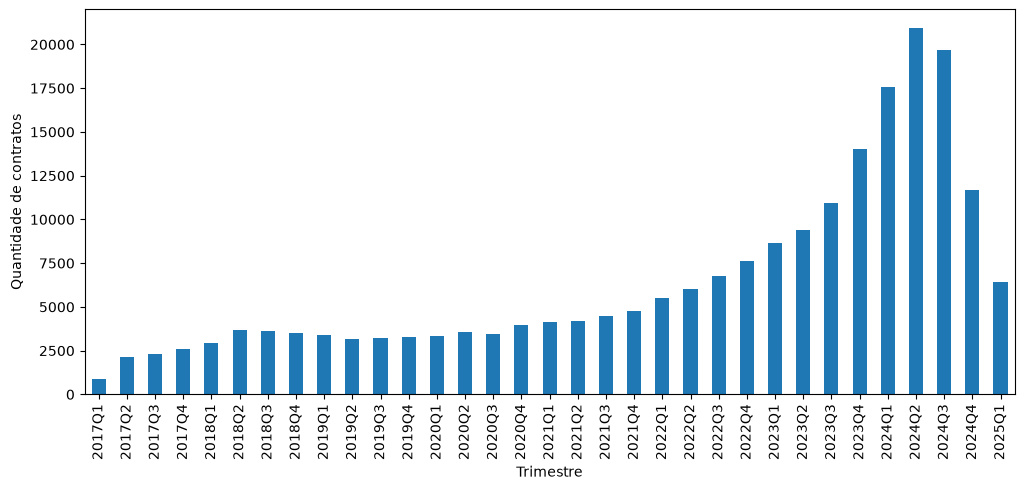

In [370]:
tri = (
    hist_emp.groupby(pd.Grouper(key="proxy_data_solicitacao", freq="QS"))
    ["id_contrato"]
    .count()
    .rename("contratos por semestre")
    .reset_index()
)
datas = tri["proxy_data_solicitacao"]

tri["proxy_data_solicitacao"] = (
    datas.dt.year.astype(str) + "Q" + datas.dt.quarter.astype(str)
)


ax = tri.plot(
    kind="bar",
    x="proxy_data_solicitacao",
    y="contratos por semestre",
    rot=90,
    legend=False,
    figsize=(12,5)
)

ax.set_xlabel("Trimestre")
ax.set_ylabel("Quantidade de contratos")

# Criando variáveis históricas e a variável Target + Merge das tabelas

### Contratos sem encerramento -> checar depois

In [636]:
# chave = ['id_contrato', 'id_cliente']
# chave_parcela = chave + ['numero_parcela']

# total_pago = (
#     parc.drop_duplicates(subset=chave_parcela)
#     .groupby(chave)['valor_pago_parcela_tot']
#     .sum(min_count=1)
#     .rename('valor_total_pago')
#     .reset_index()
# )

# checagem = df_emp.loc[['status_contrato'].eq('Aprovado')].merge(
#     total_pago, on=chave, how='left', validate='one_to_one'
# )

# sem_encerramento = checagem.loc[
#     checagem['data_encerramento'].isna()
#     & checagem['valor_solicitado'].gt(0)
#     & checagem['valor_total_pago'].round(2).ge(
#         checagem['valor_solicitado'].round(2)
#     ),
#     chave + ['valor_solicitado', 'valor_total_pago', 'data_encerramento'],
# ]

# print(len(sem_encerramento))
# display(sem_encerramento)

### Possiveis targets:

Over30mob3
Over90

Condições: 


- t1

- t30

- t60

- t90

In [314]:
parc.head(1)

,id_contrato,id_cliente,numero_parcela,versao_parcela,valor_previsto_parcela,valor_pago_parcela_tot,deficit,deficit_perc,data_prevista_pagamento,data_real_pagamento,dias_atraso_max,t1,t30,t60,t90
0,1000003,252457,1,1.000e+00,4.951e+03,4.951e+03,0.000e+00,0.000e+00,2024-11-19,2024-11-05,-14,False,False,False,False


In [321]:
c1 = (parc.t1)&(parc.deficit>1) #se atrasou qualquer numero de dias E não pagou o valor total previsto
c2 = parc.t30 #atrasou mais do que 30 dias - trocar para 90
parc['target'] = (c1|c2)
target_contrato = parc.groupby(['id_contrato', 'id_cliente'], as_index=False).agg(target=('target', 'max'))

In [322]:
target_contrato

,id_contrato,id_cliente,target
0,1000003,252457,False
1,1000013,215520,False
2,1000019,176905,False
3,1000053,399400,False
4,1000056,248219,False
...,...,...,...
122862,2870408,466246,False
122863,2870410,466247,False
122864,2870411,466247,False
122865,2870412,466247,False


In [325]:
dftr = df_emp.copy()
dftr = dftr.merge(cad[['id_cliente'] + feats_cad], on='id_cliente', how='left').sort_values(by='id_contrato')
dftr


,id_cliente,id_contrato,valor_solicitado,valor_credito,valor_bem,valor_parcela,valor_entrada,tipo_contrato,indicador_ultima_solicitacao_contrato,indicador_ultima_solicitacao_dia,indicador_seguro_contratado,indicador_ultima_solicitacao_contrato,indicador_ultima_solicitacao_dia,indicador_seguro_contratado,qtd_parcelas_planejadas,proxy_data_solicitacao,hora_solicitacao,tipo_contrato,status_contrato,tipo_pagamento,finalidade_emprestimo,tipo_cliente,faixa_rendimento,tipo_portfolio,tipo_produto,categoria_bem,combinacao_produto,setor_vendedor,canal_venda,area_venda,dia_semana_solicitacao,motivo_recusa,acompanhantes_cliente,data_nascimento,qtd_filhos,qtd_membros_familia,renda_anual,tipo_renda,ocupacao,tipo_organizacao,nivel_educacao,estado_civil,tipo_moradia,possui_carro,possui_imovel,nota_regiao_cliente,nota_regiao_cliente_cidade
168155,252457,1000003,4.706e+04,5.264e+04,4.706e+04,4.951e+03,4.275e+00,financiamento de consumo,1,1,1,1,1,1,1.200e+01,2024-10-20,13:08:12,financiamento de consumo,aprovado,dinheiro pelo banco,nao se aplica,reativado,baixa acao,ponto de venda,nao informado,audio e video,ponto de venda casa sem juros,eletronicos de consumo,rede nacional,1103,domingo,nao se aplica,desacompanhado,1986-02-16,1,3,1.575e+05,associado comercial,equipe de vendas,educacao infantil,ensino medio,casado,casa ou apartamento,0,0,2,2
81698,215520,1000013,1.350e+05,1.335e+05,1.350e+05,1.335e+04,1.350e+04,emprestimo em dinheiro,1,1,0,1,1,0,1.200e+01,2021-04-22,18:17:39,emprestimo em dinheiro,aprovado,dinheiro pelo banco,nao se aplica,novo,media,ponto de venda,nao informado,computadores,ponto de venda casa com juros,eletronicos de consumo,regional ou local,121,quinta-feira,nao se aplica,familia,2002-03-21,0,1,9.000e+04,associado comercial,equipe de vendas,entidade empresarial tipo 3,ensino medio,solteiro,casa ou apartamento,0,0,2,2
156682,176905,1000019,6.025e+04,5.137e+04,6.025e+04,6.072e+03,1.350e+04,financiamento de consumo,1,1,0,1,1,0,1.200e+01,2018-09-20,12:18:02,financiamento de consumo,aprovado,dinheiro pelo banco,nao se aplica,recorrente,alta,ponto de venda,nao informado,celular,ponto de venda celular com juros,conectividade,rede nacional,62,quinta-feira,nao se aplica,desacompanhado,1980-09-23,0,2,1.350e+05,assalariado,operarios,transporte tipo 2,ensino medio,uniao estavel,mora com os pais,1,0,3,3
37798,399400,1000053,3.568e+04,2.989e+04,3.568e+04,5.707e+03,7.200e+03,financiamento de consumo,1,1,0,1,1,0,6.000e+00,2021-03-12,15:02:06,financiamento de consumo,aprovado,dinheiro pelo banco,nao se aplica,recorrente,media,ponto de venda,nao informado,foto e cinema,ponto de venda casa com juros,eletronicos de consumo,loja fisica,129,sexta-feira,nao se aplica,desacompanhado,1997-11-12,0,1,1.800e+05,assalariado,garcons e atendentes de bar,entidade empresarial tipo 3,ensino medio,solteiro,casa ou apartamento,1,1,2,2
90082,248219,1000056,2.358e+04,2.567e+04,2.358e+04,3.750e+03,2.340e+03,credito rotativo,1,1,0,1,1,0,1.000e+01,2021-10-30,12:13:18,credito rotativo,aprovado,dinheiro pelo banco,nao se aplica,recorrente,alta,cartoes,nao informado,nao informado,cartao venda cruzada,conectividade,rede nacional,65,sabado,nao se aplica,familia,1991-11-12,1,3,1.125e+05,assalariado,equipe de vendas,industria tipo 3,ensino medio,casado,apartamento municipal,0,0,2,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
210276,466247,2870412,8.950e+05,1.041e+06,8.379e+05,1.545e+05,NaN,emprestimo em dinheiro,1,1,<NA>,1,1,<NA>,1.000e+01,2022-01-21,14:37:57,emprestimo em dinheiro,aprovado,nao informado,nao informado,recorrente,media,dinheiro,venda cruzada,nao informado,dinheiro venda cruzada: media,nao informado,central de atendimento,-1,sexta-feira,nao se aplica,nao informado,1973-11-02,0,1,2.780e+05,assalariado,equipe de vendas,nao informado,ensino medio,uniao estavel,casa ou apartamento,0,1,3,3
210277,466247,2870413,4.313e+0

In [326]:
parc

,id_contrato,id_cliente,numero_parcela,versao_parcela,valor_previsto_parcela,valor_pago_parcela_tot,deficit,deficit_perc,data_prevista_pagamento,data_real_pagamento,dias_atraso_max,t1,t30,t60,t90,target
0,1000003,252457,1,1.000e+00,4.951e+03,4.951e+03,0.000e+00,0.000e+00,2024-11-19,2024-11-05,-14,False,False,False,False,False
1,1000003,252457,2,1.000e+00,4.951e+03,4.951e+03,0.000e+00,0.000e+00,2024-12-19,2024-12-02,-17,False,False,False,False,False
2,1000003,252457,3,1.000e+00,4.951e+03,4.951e+03,0.000e+00,0.000e+00,2025-01-18,2025-01-03,-15,False,False,False,False,False
3,1000013,215520,1,1.000e+00,1.335e+04,1.335e+04,0.000e+00,0.000e+00,2021-05-23,2021-05-17,-6,False,False,False,False,False
4,1000013,215520,2,1.000e+00,1.335e+04,1.335e+04,0.000e+00,0.000e+00,2021-06-22,2021-06-16,-6,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1574406,2870412,466247,8,0.000e+00,1.545e+05,1.545e+05,0.000e+00,0.000e+00,2022-09-27,2022-09-27,0,False,False,False,False,False
1574407,2870412,466247,9,0.000e+00,1.545e+05,1.545e+05,0.000e+00,0.000e+00,2022-10-27,2022-10-27,0,False,False,False,False,False
1574408,2870412,466247,10,0.000e+00,1.545e+05,3.096e+05,-1.552e+05,-1.005e+00,2022-11-26,2022-11-27,1,True,False,False,False,False
1574409,2870415,466248,1,1.000e+00,4.912e+02,4.912e+02,0.000e+00,0.000e+00,2024-12-15,2024-12-15,0,False,False,False,False,False


In [319]:
# target_contrato, cad feats_cad, df_emp feats_emp
list_colunas = ['id_cliente'] + feats_cad
dftr = cad[list_colunas].copy()
dftr = dftr.merge(df_emp[['id_cliente', 'id_contrato', 'proxy_data_solicitacao'] + feats_emp], on='id_cliente', how='left')
dftr = dftr.loc[dftr.id_contrato.notnull()]
dftr = dftr.merge(target_contrato, on=['id_cliente', 'id_contrato'], how='left')

dftr['idade_solicitacao'] = (pd.to_datetime(dftr.proxy_data_solicitacao, format='%Y-%m-%d')
                            - pd.to_datetime(dftr.data_nascimento.replace('31/02/1990', '1990-03-01'), format='%Y-%m-%d')).dt.days/365
idade_bins = [-np.inf, 18, 25, 35, 45, 55, 65, 75, 95, np.inf]
labels = [f'{idade_bins[i]} - {idade_bins[i+1]}' for i in range(len(idade_bins)-1)]
dftr['idade_solicitacao_cat'] = pd.cut(dftr.idade_solicitacao, bins=idade_bins, labels=labels)
dftr.loc[dftr.qtd_membros_familia<1, 'qtd_membros_familia'] = 1
dftr['qtd_membros_familia'] = dftr.qtd_membros_familia.fillna(1)

def fix_renda(txt):
    rgx = '[\d,]'
    res = ''.join(re.findall(rgx, txt)).replace(',', '.')
    if res == '':
        return '0'
    return res

dftr['renda_anual'] = dftr.renda_anual.apply(lambda x: fix_renda(x)).astype(float)
dftr['renda_por_membro'] = dftr.renda_anual/dftr.qtd_membros_familia

dftr[['nota_regiao_cliente', 'nota_regiao_cliente_cidade']] = dftr[['nota_regiao_cliente', 'nota_regiao_cliente_cidade']].astype(str)

feats_eng = ['idade_solicitacao_cat', 'renda_por_membro'] # numero de inadimplencias anteriores por cliente
# labels

ValueError: cannot assemble with duplicate keys

## Teste

In [80]:
# OVER30 MOB3 por contrato: saldo vencido ha mais de 30 dias no MOB3.
chave_mob3 = ["id_contrato", "id_cliente"]
chave_parcela = chave_mob3 + ["numero_parcela"]
# Ajuste conforme a data ate a qual o historico esta completo.
data_corte_mob3 = pd.Timestamp("2025-01-31")

contratos_mob3 = hist_emp[chave_mob3].copy()
liberacao = pd.to_datetime(hist_emp["data_liberacao"])
decisao = pd.to_datetime(hist_emp["data_decisao"])
contratos_mob3["usa_proxy_concessao"] = liberacao.isna() & decisao.notna()
contratos_mob3["data_mob3"] = liberacao.fillna(decisao) + pd.DateOffset(months=3)
elegiveis_mob3 = contratos_mob3.loc[contratos_mob3["data_mob3"].le(data_corte_mob3)]

campos = chave_parcela + [
    "data_prevista_pagamento", "data_real_pagamento",
    "valor_previsto_parcela", "valor_pago_parcela",
]
mov = hist_parc[campos].merge(
    elegiveis_mob3[chave_mob3 + ["data_mob3"]], on=chave_mob3, validate="many_to_one"
)
mov["dias_no_mob3"] = (mov["data_mob3"] - mov["data_prevista_pagamento"]).dt.days
data_pagamento = mov["data_real_pagamento"]
valor_pago = mov["valor_pago_parcela"]
pago_no_prazo_observado = data_pagamento.le(mov["data_mob3"])
mov["pagamento_incerto"] = (
    (data_pagamento.isna() & valor_pago.gt(0))
    | (pago_no_prazo_observado & valor_pago.isna())
)

parcelas_mob3 = mov.groupby(chave_parcela).agg(
    atraso_min=("dias_no_mob3", "min"),
    atraso_max=("dias_no_mob3", "max"),
    previsto_min=("valor_previsto_parcela", "min"),
    previsto_max=("valor_previsto_parcela", "max"),
    pagamento_incerto=("pagamento_incerto", "any"),
)

# Compare dois cenarios para valores distintos na mesma data:
# considerar apenas o maior valor ou somar todos os valores distintos.
chave_pagamento = chave_parcela + ["data_real_pagamento"]
pagos = mov.loc[
    pago_no_prazo_observado & valor_pago.notna(),
    chave_pagamento + ["valor_pago_parcela"],
].drop_duplicates()
pagos_por_dia = pagos.groupby(chave_pagamento)["valor_pago_parcela"].agg(
    pago_min="max", pago_max="sum"
)
parcelas_mob3 = parcelas_mob3.join(pagos_por_dia.groupby(level=chave_parcela).sum())
saldo_min = parcelas_mob3["previsto_min"] - parcelas_mob3["pago_max"].fillna(0)
saldo_max = parcelas_mob3["previsto_max"] - parcelas_mob3["pago_min"].fillna(0)

em_atraso = (
    parcelas_mob3["atraso_min"].gt(30)
    & saldo_min.gt(0.01)
    & ~parcelas_mob3["pagamento_incerto"]
)
sem_atraso = parcelas_mob3["atraso_max"].le(30) | saldo_max.le(0.01)
por_contrato = (
    parcelas_mob3.assign(em_atraso=em_atraso, sem_atraso=sem_atraso)
    .groupby(level=chave_mob3)
    .agg(alguma_em_atraso=("em_atraso", "any"), todas_sem_atraso=("sem_atraso", "all"))
)
por_contrato["over30_mob3"] = (
    por_contrato["alguma_em_atraso"].astype("boolean")
    .mask(~(por_contrato["alguma_em_atraso"] | por_contrato["todas_sem_atraso"]))
)
contratos_mob3 = contratos_mob3.join(por_contrato["over30_mob3"], on=chave_mob3)
taxa_over30_mob3 = contratos_mob3["over30_mob3"].mean() * 100

resumo_mob3 = pd.Series({
    "Contratos com MOB3 ate o corte": len(elegiveis_mob3),
    "Contratos com alvo calculavel": contratos_mob3["over30_mob3"].count(),
    "Contratos OVER30 MOB3": contratos_mob3["over30_mob3"].sum(),
    "OVER30 MOB3 (%)": taxa_over30_mob3,
})
resumo_mob3

Contratos com MOB3 ate o corte   1.988e+05
Contratos com alvo calculavel    1.204e+05
Contratos OVER30 MOB3            1.814e+03
OVER30 MOB3 (%)                  1.506e+00
dtype: float64

## Treino

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, roc_auc_score, accuracy_score, precision_score, recall_score
import seaborn as sns

from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

In [ ]:
df = dftr.copy()
target = 'target'
FREQ_ENC_MINIMUM_UNIQUE = 5

In [ ]:
X = df[feats_cad + feats_emp + feats_eng].drop('data_nascimento', axis=1)
y = df[target].astype('boolean').fillna(False).astype('int8')
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [ ]:
# Identify feature types
num_features = X.select_dtypes(include=np.number).columns.tolist()
cat_features = X.select_dtypes(exclude=np.number).columns.tolist()
cat_freq_features = np.array(cat_features)[X_train[cat_features].nunique() > FREQ_ENC_MINIMUM_UNIQUE]
cat_freq_features = [str(i) for i in cat_freq_features]
cat_dummy_features = [i for i in cat_features if i not in cat_freq_features]

# Se > conf (FREQ_ENC_MINIMUM_UNIQUE) valores unicos, Fencoding, do contrário, onehot.
class FrequencyEncoder(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.feature_names_in_ = np.array(X.columns, dtype=object)
        self.freq_maps_ = {}
        for col in X.columns:
            self.freq_maps_[col] = (
                X[col].value_counts(normalize=True).to_dict()
            )
        return self

    def transform(self, X):
        X = pd.DataFrame(
            X,
            columns=self.feature_names_in_
        ).copy()
        for col in X.columns:
            X[col] = X[col].map(
                self.freq_maps_[col]
            ).fillna(0)
        return X.to_numpy()

    def get_feature_names_out(self, input_features=None):
        if input_features is None:
            input_features = self.feature_names_in_
        return np.asarray(input_features, dtype=object)



num_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="median",
        add_indicator=True
    )),
    ("scaler", StandardScaler())
])

cat_freq_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", FrequencyEncoder())
])

cat_dummy_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder())
])

preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_features),
    ("cat_freq", cat_freq_pipeline, cat_freq_features),
    ("cat_dummy", cat_dummy_pipeline, cat_dummy_features)
])

In [ ]:
models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "LightGBM": LGBMClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=-1,
        num_leaves=31,
        random_state=42,
        verbosity=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1
    ),

    # "Logistic": LogisticRegression(
    # )
}


In [ ]:
results = {}
fitted_models = {}
feature_names = None

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    results[name] = {
        "f1": f1_score(y_test, predictions),
        "roc_auc": roc_auc_score(y_test, predictions),
        "accuracy": accuracy_score(y_test, predictions),
        "precision": precision_score(y_test, predictions),
        "recall": recall_score(y_test, predictions)
    }

    fitted_models[name] = pipeline

    if feature_names is None:
        feature_names = (
            pipeline.named_steps["preprocessor"]
            .get_feature_names_out()
        )

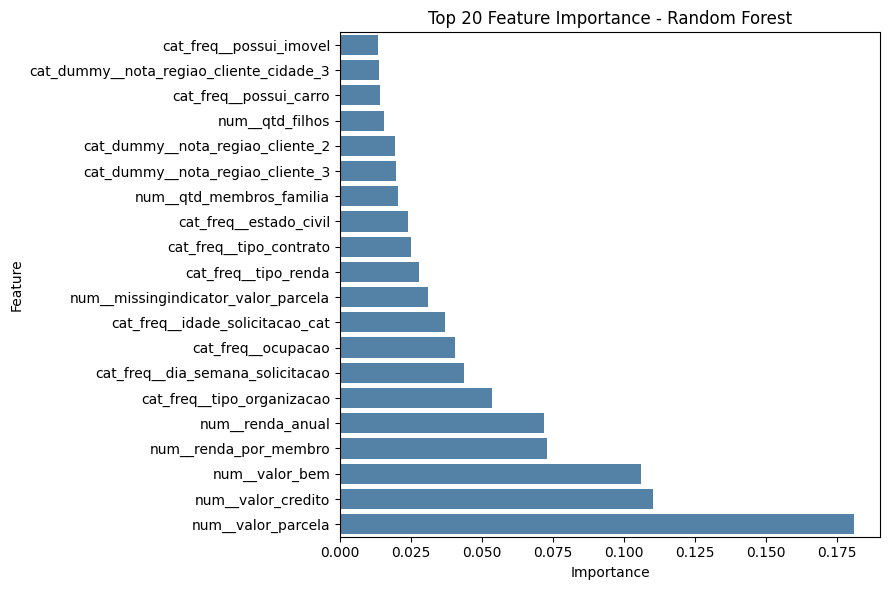

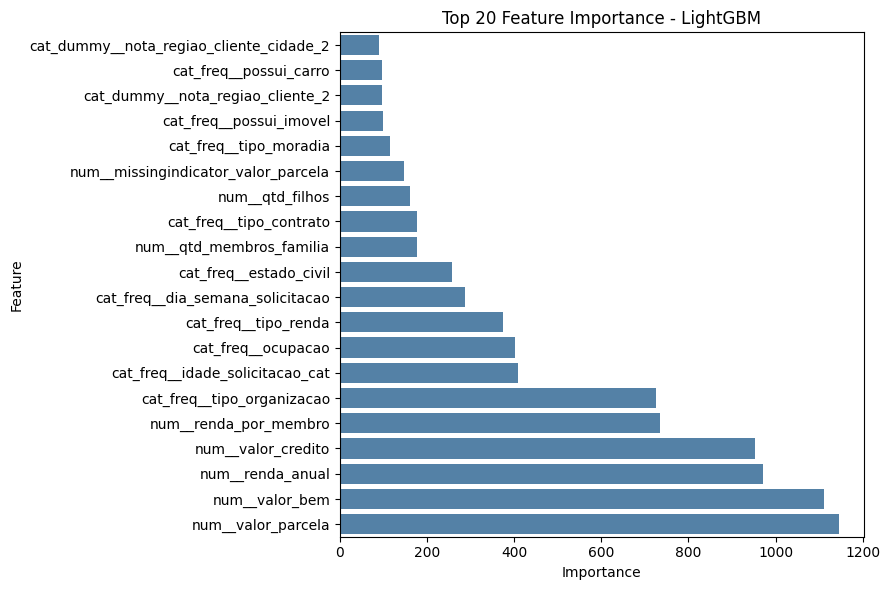

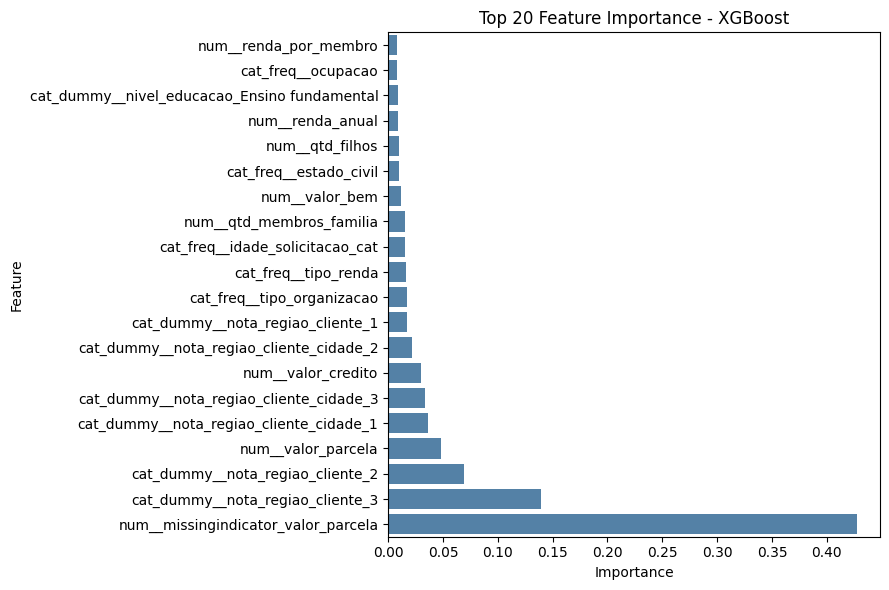

In [ ]:
def get_feature_importance(pipeline, feature_names):

    model = pipeline.named_steps["model"]
    if hasattr(model, "feature_importances_"):
        importance = model.feature_importances_
    elif hasattr(model, "coef_"):
        importance = np.abs(model.coef_)
    else:
        raise ValueError("Model does not provide feature importance.")
    return pd.Series(
        importance,
        index=feature_names
    ).sort_values(ascending=False)

# Plot importance for each model

for name, pipeline in fitted_models.items():
    importance = get_feature_importance(
        pipeline,
        feature_names
    ).head(20).sort_values()
    plt.figure(figsize=(9, 6))
    sns.barplot(
        x=importance.values,
        y=importance.index,
        color="steelblue"
    )

    plt.title(f"Top 20 Feature Importance - {name}")
    plt.xlabel("Importance")
    plt.ylabel("Feature")
    plt.tight_layout()
    plt.show()


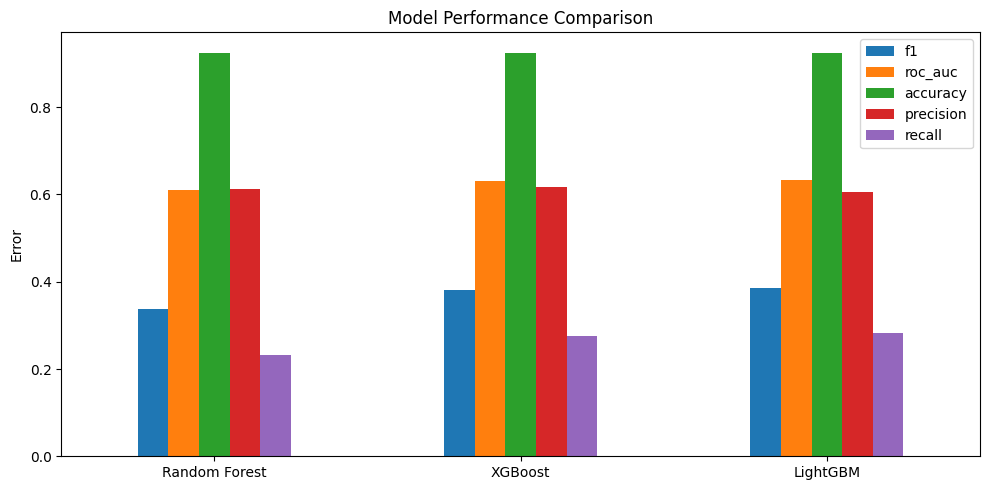

<Axes: >

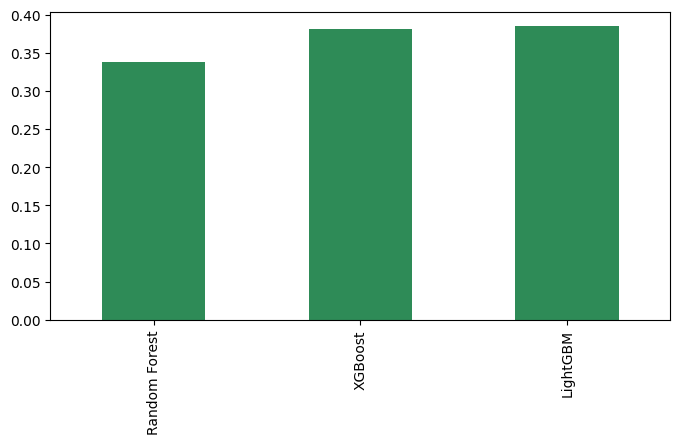

In [ ]:
# ============================================================
# 7. MODEL COMPARISON
# ============================================================

results_df.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Model Performance Comparison")
plt.ylabel("Error")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

results_df["f1"].plot(
    kind="bar",
    figsize=(8, 4),
    color="seagreen"
)

In [ ]:
import optuna

MODEL_NAME = "lightgbm"  # "randomforest" or "lightgbm"

N_TRIALS = 10
CV_FOLDS = 5
RANDOM_STATE = 32


# ============================================================
# 2. OPTUNA OBJECTIVE
# ============================================================

def objective(trial):

    if MODEL_NAME == "randomforest":
        model = RandomForestClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators", 200, 1000, step=100
            ),
            max_depth=trial.suggest_int(
                "max_depth", 3, 30
            ),
            min_samples_split=trial.suggest_int(
                "min_samples_split", 2, 20
            ),
            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf", 1, 10
            ),
            max_features=trial.suggest_categorical(
                "max_features", ["sqrt", "log2", 1.0]
            ),
            random_state=RANDOM_STATE,
            n_jobs=-1
        )

    elif MODEL_NAME == "lightgbm":

        model = LGBMClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators", 200, 1500, step=100
            ),
            learning_rate=trial.suggest_float(
                "learning_rate", 0.005, 0.15, log=True
            ),
            num_leaves=trial.suggest_int(
                "num_leaves", 10, 100
            ),
            max_depth=trial.suggest_int(
                "max_depth", 3, 15
            ),
            min_child_samples=trial.suggest_int(
                "min_child_samples", 5, 50
            ),
            subsample=trial.suggest_float(
                "subsample", 0.6, 1.0
            ),
            colsample_bytree=trial.suggest_float(
                "colsample_bytree", 0.6, 1.0
            ),
            reg_alpha=trial.suggest_float(
                "reg_alpha", 1e-4, 10.0, log=True
            ),
            reg_lambda=trial.suggest_float(
                "reg_lambda", 1e-4, 10.0, log=True
            ),
            random_state=RANDOM_STATE,
            verbosity=-1,
            n_jobs=-1
        )

    else:
        raise ValueError("Unsupported model")

    # Full pipeline
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    # Cross-validation
    cv = KFold(
        n_splits=CV_FOLDS,
        shuffle=True,
        random_state=RANDOM_STATE
    )

    scores = cross_val_score(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring="f1",
        n_jobs=1
    )

    return -scores.mean()


# ============================================================
# 3. OPTIMIZATION
# ============================================================

study = optuna.create_study(
    direction="minimize",
    study_name=f"{MODEL_NAME}_optimization"
)

study.optimize(
    objective,
    n_trials=N_TRIALS,
    show_progress_bar=True
)

[I 2026-11-22 18:07:46,056] A new study created in memory with name: lightgbm_optimization


  0%|          | 0/10 [00:00<?, ?it/s]

[I 2026-11-22 18:07:54,693] Trial 0 finished with value: -0.3600676484057333 and parameters: {'n_estimators': 200, 'learning_rate': 0.14413198475343855, 'num_leaves': 73, 'max_depth': 4, 'min_child_samples': 48, 'subsample': 0.8539565370240245, 'colsample_bytree': 0.7609844375255574, 'reg_alpha': 0.0005313513018384012, 'reg_lambda': 0.012627710308796383}. Best is trial 0 with value: -0.3600676484057333.
[I 2026-11-22 18:08:43,433] Trial 1 finished with value: -0.3813393808637427 and parameters: {'n_estimators': 900, 'learning_rate': 0.1440532196463823, 'num_leaves': 31, 'max_depth': 12, 'min_child_samples': 12, 'subsample': 0.6370143207484867, 'colsample_bytree': 0.7935821010802382, 'reg_alpha': 0.02122489197509044, 'reg_lambda': 0.026255128114845632}. Best is trial 1 with value: -0.3813393808637427.
[I 2026-11-22 18:09:16,309] Trial 2 finished with value: -0.3865509944061012 and parameters: {'n_estimators': 400, 'learning_rate': 0.04541004110132533, 'num_leaves': 54, 'max_depth': 8, '

In [ ]:
import optuna

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier


MODEL_NAME = "lightgbm"  # "randomforest" or "lightgbm"

N_TRIALS = 3
CV_FOLDS = 5
RANDOM_STATE = 32

def objective(trial):

    if MODEL_NAME == "randomforest":

        model = RandomForestClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators", 200, 1000, step=100
            ),
            max_depth=trial.suggest_int(
                "max_depth", 3, 30
            ),
            min_samples_split=trial.suggest_int(
                "min_samples_split", 2, 20
            ),
            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf", 1, 10
            ),
            max_features=trial.suggest_categorical(
                "max_features", ["sqrt", "log2", 1.0]
            ),
            random_state=RANDOM_STATE,
            n_jobs=-1
        )

    elif MODEL_NAME == "lightgbm":

        model = LGBMClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators", 200, 1500, step=100
            ),
            learning_rate=trial.suggest_float(
                "learning_rate", 0.005, 0.15, log=True
            ),
            num_leaves=trial.suggest_int(
                "num_leaves", 10, 100
            ),
            max_depth=trial.suggest_int(
                "max_depth", 3, 15
            ),
            min_child_samples=trial.suggest_int(
                "min_child_samples", 5, 50
            ),
            subsample=trial.suggest_float(
                "subsample", 0.6, 1.0
            ),
            colsample_bytree=trial.suggest_float(
                "colsample_bytree", 0.6, 1.0
            ),
            reg_alpha=trial.suggest_float(
                "reg_alpha", 1e-4, 10.0, log=True
            ),
            reg_lambda=trial.suggest_float(
                "reg_lambda", 1e-4, 10.0, log=True
            ),
            random_state=RANDOM_STATE,
            verbosity=-1,
            n_jobs=-1
        )

    else:
        raise ValueError("Unsupported model")
    pipeline = ImbPipeline([
        ("preprocessor", preprocessor),
        ("smote", SMOTE(
            random_state=RANDOM_STATE,
            k_neighbors=5
        )),
        ("model", model)
    ])
    cv = StratifiedKFold(
        n_splits=CV_FOLDS,
        shuffle=True,
        random_state=RANDOM_STATE
    )

    scores = cross_val_score(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring="f1",
        n_jobs=1
    )

    return -scores.mean()

study = optuna.create_study(
    direction="minimize",
    study_name=f"{MODEL_NAME}_optimization"
)
study.optimize(
    objective,
    n_trials=N_TRIALS,
    show_progress_bar=True
)


print("Best F1-score:", -study.best_value)
print("Best parameters:", study.best_params)


[I 2026-11-22 18:37:02,781] A new study created in memory with name: lightgbm_optimization


  0%|          | 0/3 [00:00<?, ?it/s]

[W 2026-11-22 18:37:03,050] Trial 0 failed with parameters: {'n_estimators': 1100, 'learning_rate': 0.10295072699595681, 'num_leaves': 25, 'max_depth': 3, 'min_child_samples': 12, 'subsample': 0.6171081073800376, 'colsample_bytree': 0.933073531176205, 'reg_alpha': 4.224073602631322, 'reg_lambda': 0.02149239075877278} because of the following error: ValueError('\nAll the 5 fits failed.\nIt is very likely that your model is misconfigured.\nYou can try to debug the error by setting error_score=\'raise\'.\n\nBelow are more details about the failures:\n--------------------------------------------------------------------------------\n3 fits failed with the following error:\nTraceback (most recent call last):\n  File "/home/joao/venvst/lib/python3.12/site-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score\n    estimator.fit(X_train, y_train, **fit_params)\n  File "/home/joao/venvst/lib/python3.12/site-packages/sklearn/base.py", line 1389, in wrapper\n    return fit_

ValueError: 
All the 5 fits failed.
It is very likely that your model is misconfigured.
You can try to debug the error by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
3 fits failed with the following error:
Traceback (most recent call last):
  File "/home/joao/venvst/lib/python3.12/site-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "/home/joao/venvst/lib/python3.12/site-packages/sklearn/base.py", line 1389, in wrapper
    return fit_method(estimator, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/joao/venvst/lib/python3.12/site-packages/imblearn/pipeline.py", line 514, in fit
    Xt, yt = self._fit(X, y, routed_params, raw_params=params)
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/joao/venvst/lib/python3.12/site-packages/imbl

Best CV f1: -0.3883324652187423
Best parameters: {'n_estimators': 700, 'learning_rate': 0.04581321933759033, 'num_leaves': 85, 'max_depth': 14, 'min_child_samples': 6, 'subsample': 0.8626537271218433, 'colsample_bytree': 0.8119380978076145, 'reg_alpha': 0.026818927637299244, 'reg_lambda': 0.0068340595158395065}

Test performance:
f1: 0.4012055000941797


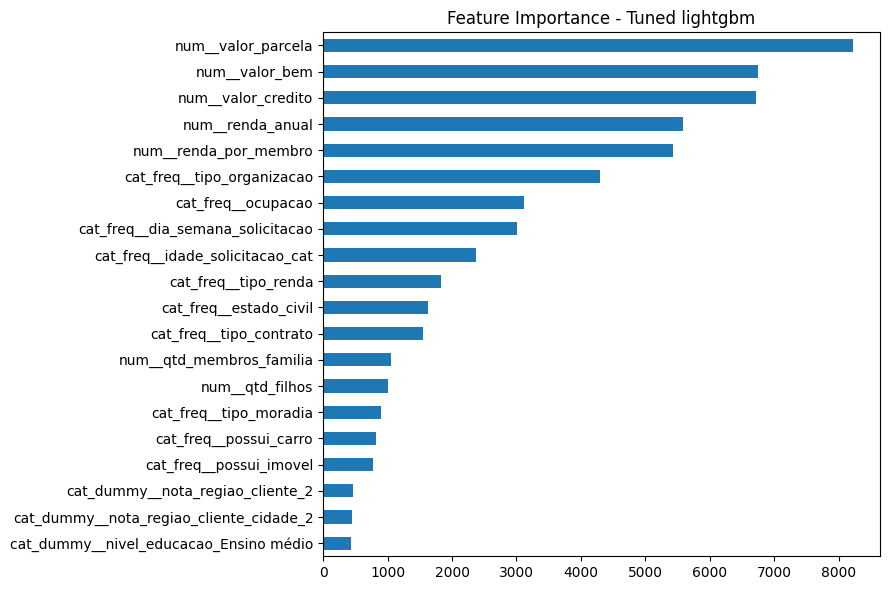

In [ ]:
print("Best CV f1:", study.best_value)
print("Best parameters:", study.best_params)


# ============================================================
# 4. FIT BEST MODEL
# ============================================================

if MODEL_NAME == "randomforest":

    best_model = RandomForestClassifier(
        **study.best_params,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

elif MODEL_NAME == "lightgbm":

    best_model = LGBMClassifier(
        **study.best_params,
        random_state=RANDOM_STATE,
        verbosity=-1,
        n_jobs=-1
    )


best_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", best_model)
])

best_pipeline.fit(X_train, y_train)


# ============================================================
# 5. TEST EVALUATION
# ============================================================

predictions = best_pipeline.predict(X_test)

print("\nTest performance:")
print("f1:", f1_score(y_test.fillna(False), predictions))


# ============================================================
# 6. FEATURE IMPORTANCE
# ============================================================

feature_names = (
    best_pipeline.named_steps["preprocessor"]
    .get_feature_names_out()
)

model = best_pipeline.named_steps["model"]

importance = pd.Series(
    model.feature_importances_,
    index=feature_names
).sort_values(ascending=False)

importance.head(20).sort_values().plot(
    kind="barh",
    figsize=(9, 6),
    title=f"Feature Importance - Tuned {MODEL_NAME}"
)

plt.tight_layout()
plt.show()

In [ ]:
def get_original_feature_name(preprocessor, transformed_name):
    transformer_name, feature_name = transformed_name.split("__", 1)
    transformers = {
        name: (transformer, columns)
        for name, transformer, columns in preprocessor.transformers_
    }
    transformer, columns = transformers[transformer_name]
    if transformer_name == "num":
        if feature_name.startswith("missingindicator_"):
            return feature_name.replace("missingindicator_", "", 1)
        return feature_name
    if transformer_name == "cat_dummy":
        encoder = transformer.named_steps["encoder"]
        encoded_names = encoder.get_feature_names_out(columns)
        for col, encoded in zip(
            [col for col in columns for _ in encoder.categories_[list(columns).index(col)]],
            encoded_names
        ):
            if encoded == feature_name:
                return col
        raise ValueError(f"Feature not found: {transformed_name}")
    if transformer_name == "cat_freq":
        return feature_name
    return feature_name
    
get_original_feature_name(pipeline['preprocessor'], 'num__valor_parcela')

'valor_parcela'

In [ ]:
n_feats = [29, 20, 15, 10, 5]
results = {}
params = {'n_estimators': 700, 'learning_rate': 0.04581321933759033, 'num_leaves': 85, 
          'max_depth': 14, 'min_child_samples': 6, 'subsample': 0.8626537271218433, 'colsample_bytree': 0.8119380978076145,
          'reg_alpha': 0.026818927637299244, 'reg_lambda': 0.0068340595158395065}

model = LGBMClassifier(
        **params,
        random_state=32,
        verbosity=-1,
        n_jobs=-1
    )
feat_names_proc = [i for i in importance.index]

for n in n_feats:

    _feats = feat_names_proc[:n]
    _feats = list(set([get_original_feature_name(best_pipeline['preprocessor'], i) for i in _feats]))
    
    num_pipeline = Pipeline([
        ("imputer", SimpleImputer(
            strategy="median",
            add_indicator=True
        )),
        ("scaler", StandardScaler())
    ])
    cat_freq_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", FrequencyEncoder())
    ])
    cat_dummy_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder())
    ])
    preprocessor = ColumnTransformer([
        ("num", num_pipeline, [i for i in num_features if i in _feats]),
        ("cat_freq", cat_freq_pipeline, [i for i in cat_freq_features if i in _feats]),
        ("cat_dummy", cat_dummy_pipeline, [i for i in cat_dummy_features if i in _feats])
    ])
    _pipeline = ImbPipeline([
        ("preprocessor", preprocessor),
        ("smote", SMOTE(
            random_state=32,
            k_neighbors=5
        )),
        ("model", model)
    ])
    cv = StratifiedKFold(
        n_splits=CV_FOLDS,
        shuffle=True,
        random_state=RANDOM_STATE
    )

    _pipeline.fit(X_train[_feats], y_train)
    predictions = _pipeline.predict(X_test[_feats])
    results[f'{n}_feats'] = {
        "f1": f1_score(y_test, predictions),
        "roc_auc": roc_auc_score(y_test, predictions),
        "accuracy": accuracy_score(y_test, predictions),
        "precision": precision_score(y_test, predictions),
        "recall": recall_score(y_test, predictions)
    }
    fitted_models[f'{n}_feats'] = _pipeline
    if feature_names is None:
        feature_names = (
            pipeline.named_steps["preprocessor"]
            .get_feature_names_out()
        )

In [ ]:
results_df = pd.DataFrame(results).T.sort_values("f1", ascending=False)

print("\nModel performance:")
print(results_df.round(4))


Model performance:
              f1  roc_auc  accuracy  precision  recall
5_feats   0.4346   0.7203    0.8870     0.3732  0.5202
10_feats  0.4194   0.6510    0.9258     0.6043  0.3211
29_feats  0.4029   0.6416    0.9256     0.6102  0.3008
20_feats  0.4029   0.6416    0.9256     0.6102  0.3008
15_feats  0.3998   0.6390    0.9263     0.6242  0.2941


In [ ]:
feat_names_proc[:5]

['num__valor_parcela',
 'num__valor_bem',
 'num__valor_credito',
 'num__renda_anual',
 'num__renda_por_membro']